In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the final prediction results
df = pd.read_csv(
    "/content/01_emotion_6075_predictions.csv"
)

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

# Check essential columns
required_columns = ["song_id", "year", "predicted_emotion"]

assert all(col in df.columns for col in required_columns), \
    "Some required columns are missing!"

assert len(df) == 6075, "Unexpected number of records!"
assert df["song_id"].is_unique, "Duplicate song IDs found!"

df["year"] = pd.to_numeric(df["year"], errors="raise")
df["predicted_emotion"] = (
    df["predicted_emotion"].astype(str).str.strip()
)

emotion_order = ["Happy", "Relaxed", "Sad", "Angry"]

assert df["year"].notna().all()
assert df["predicted_emotion"].isin(emotion_order).all()

print("\nTotal songs:", len(df))
print("Year range:", df["year"].min(), "-", df["year"].max())
print("\nEmotion categories:")
print(df["predicted_emotion"].value_counts())

display(df.head())


Dataset shape: (6075, 11)

Columns:
['song_id', 'song_title', 'artist', 'year', 'rank', 'predicted_emotion', 'emotion_confidence', 'prob_happy', 'prob_relaxed', 'prob_sad', 'prob_angry']

Total songs: 6075
Year range: 1959 - 2023

Emotion categories:
predicted_emotion
Relaxed    2525
Happy      1904
Angry       847
Sad         799
Name: count, dtype: int64


,song_id,song_title,artist,year,rank,predicted_emotion,emotion_confidence,prob_happy,prob_relaxed,prob_sad,prob_angry
0,1,The Battle Of New Orleans,Johnny Horton,1959,1,Angry,0.702491,0.044382,0.128885,0.124242,0.702491
1,2,Mack The Knife,Bobby Darin,1959,2,Sad,0.414511,0.055524,0.346569,0.414511,0.183396
2,3,Personality,Lloyd Price,1959,3,Happy,0.829837,0.829837,0.147409,0.012689,0.010066
3,4,Venus,Frankie Avalon,1959,4,Happy,0.824313,0.824313,0.153370,0.012328,0.009990
4,5,Lonely Boy,Paul Anka,1959,5,Relaxed,0.569719,0.127874,0.569719,0.279449,0.022958


Overall Emotion Distribution


,Emotion,Count,Percentage (%)
0,Happy,1904,31.34
1,Relaxed,2525,41.56
2,Sad,799,13.15
3,Angry,847,13.94


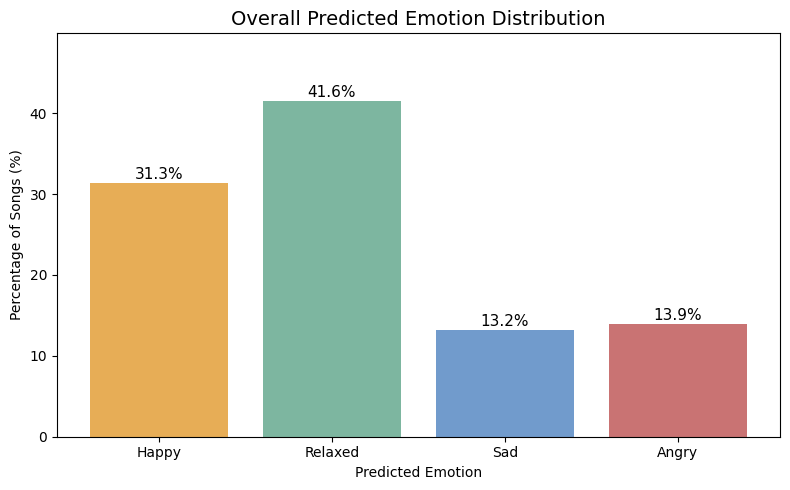

In [2]:

# 1. Calculate overall distribution
emotion_counts = (
    df["predicted_emotion"]
    .value_counts()
    .reindex(emotion_order, fill_value=0)
)

emotion_percentages = emotion_counts / len(df) * 100

overall_summary = pd.DataFrame({
    "Emotion": emotion_order,
    "Count": emotion_counts.values,
    "Percentage (%)": emotion_percentages.values
})

print("Overall Emotion Distribution")
display(overall_summary.round(2))

# 2. Plot
fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    overall_summary["Emotion"],
    overall_summary["Percentage (%)"],
    color=["#E7AD56", "#7DB6A0", "#719BCC", "#C97373"]
)

for bar, pct in zip(
    bars, overall_summary["Percentage (%)"]
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.5,
        f"{pct:.1f}%",
        ha="center",
        fontsize=11
    )

ax.set_title(
    "Overall Predicted Emotion Distribution",
    fontsize=14
)
ax.set_xlabel("Predicted Emotion")
ax.set_ylabel("Percentage of Songs (%)")
ax.set_ylim(0, overall_summary["Percentage (%)"].max() * 1.2)

plt.tight_layout()
plt.savefig(
    "/content/overall_emotion_distribution.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


Emotion Distribution by Decade (%)


predicted_emotion,Total Songs,Happy,Relaxed,Sad,Angry
1959,82,40.24,41.46,13.41,4.88
1960s,911,41.05,38.31,14.82,5.82
1970s,932,44.42,39.16,12.12,4.29
1980s,967,38.37,43.02,13.96,4.65
1990s,946,32.66,41.75,13.64,11.95
2000s,954,17.71,45.60,15.09,21.59
2010s,944,18.86,41.63,9.75,29.77
2020-2023,339,16.52,40.71,11.80,30.97


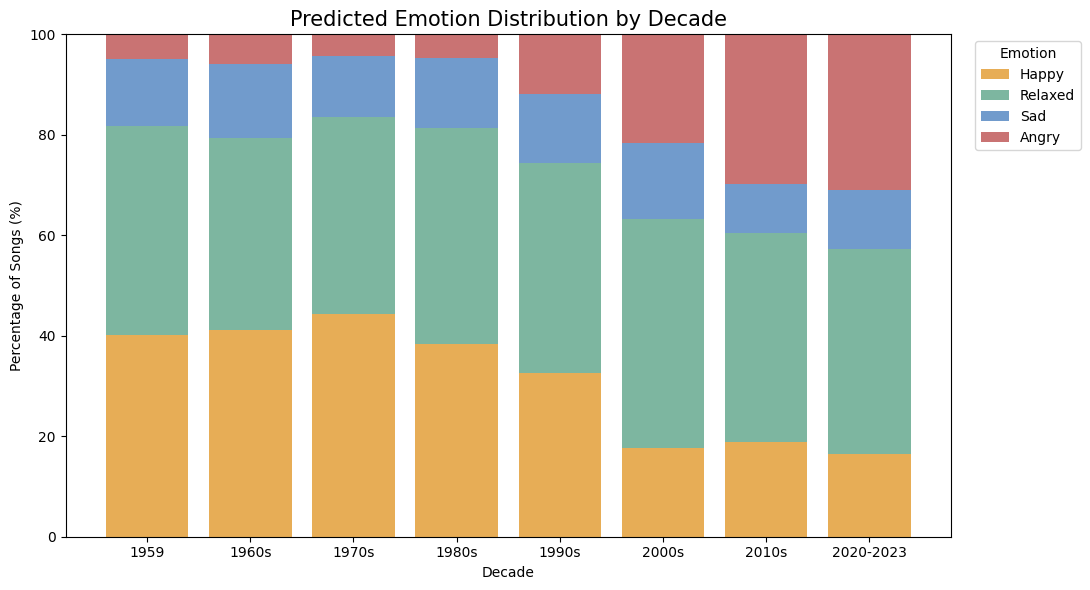

In [3]:

# Analysis 2: Emotion Distribution by Decade

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

emotion_order = ["Happy", "Relaxed", "Sad", "Angry"]

colors = {
    "Happy": "#E7AD56",
    "Relaxed": "#7DB6A0",
    "Sad": "#719BCC",
    "Angry": "#C97373"
}

# 1. Group songs into decades
df["decade"] = (df["year"].astype(int) // 10) * 10

# 2. Count each emotion within each decade
decade_counts = pd.crosstab(
    df["decade"],
    df["predicted_emotion"]
).reindex(columns=emotion_order, fill_value=0)

# 3. Calculate within-decade percentages
decade_pct = decade_counts.div(
    decade_counts.sum(axis=1), axis=0
) * 100

# 4. Create readable labels
def decade_name(year):
    if year == 1950:
        return "1959"
    if year == 2020:
        return "2020-2023"
    return f"{year}s"

decade_pct.index = [
    decade_name(d) for d in decade_pct.index
]

# 5. Summary table
decade_summary = decade_pct.copy()
decade_summary.insert(
    0, "Total Songs",
    decade_counts.sum(axis=1).values
)

print("Emotion Distribution by Decade (%)")
display(decade_summary.round(2))

# 6. Plot 100% stacked bar chart
fig, ax = plt.subplots(figsize=(11, 6))
bottom = np.zeros(len(decade_pct))

for emotion in emotion_order:
    values = decade_pct[emotion].values

    ax.bar(
        decade_pct.index,
        values,
        bottom=bottom,
        color=colors[emotion],
        label=emotion
    )

    bottom += values

ax.set_title(
    "Predicted Emotion Distribution by Decade",
    fontsize=15
)
ax.set_xlabel("Decade")
ax.set_ylabel("Percentage of Songs (%)")
ax.set_ylim(0, 100)
ax.legend(
    title="Emotion",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()

plt.savefig(
    "/content/emotion_distribution_by_decade.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 7. Save numerical results
decade_summary.to_csv(
    "/content/emotion_summary_by_decade.csv",
    index_label="Decade"
)


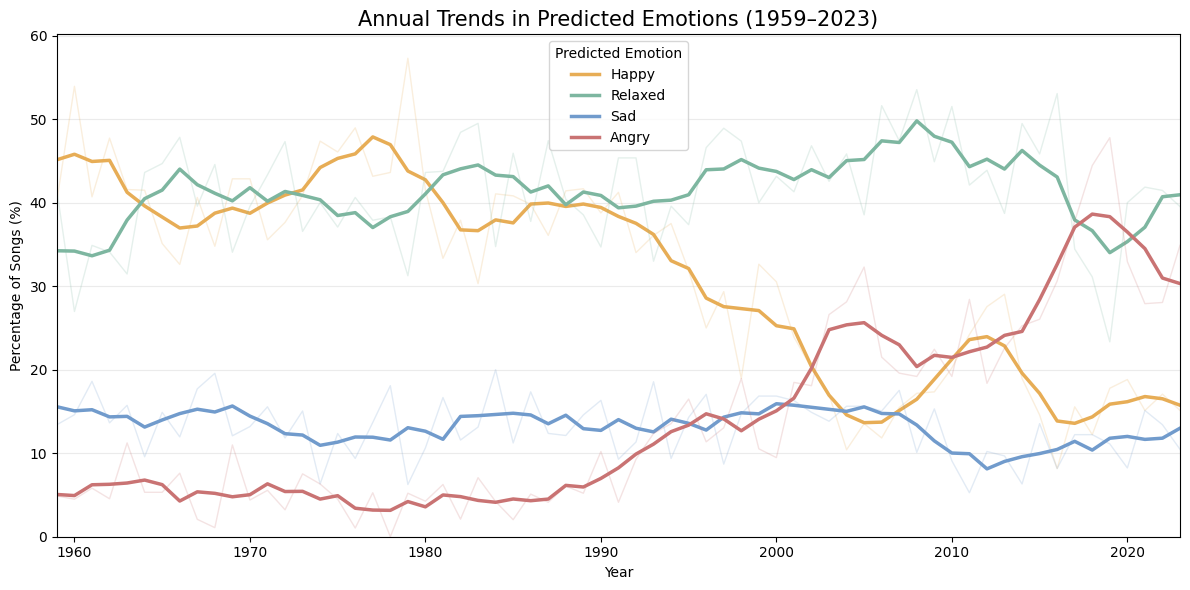

Annual emotion trends completed!


In [4]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

emotion_order = ["Happy", "Relaxed", "Sad", "Angry"]

colors = {
    "Happy": "#E7AD56",
    "Relaxed": "#7DB6A0",
    "Sad": "#719BCC",
    "Angry": "#C97373"
}

# 1. Count predicted emotions by year
year_counts = pd.crosstab(
    df["year"].astype(int),
    df["predicted_emotion"]
).reindex(columns=emotion_order, fill_value=0).sort_index()

# 2. Calculate yearly percentages
year_pct = (
    year_counts.div(
        year_counts.sum(axis=1), axis=0
    ) * 100
)

# 3. Five-year moving average
# Aggregate counts first, so years with different
# numbers of songs are weighted appropriately.
rolling_counts = year_counts.rolling(
    window=5,
    center=True,
    min_periods=3
).sum()

rolling_pct = rolling_counts.div(
    rolling_counts.sum(axis=1),
    axis=0
) * 100

# 4. Draw annual trends
fig, ax = plt.subplots(figsize=(12, 6))

for emotion in emotion_order:

    # Raw annual percentages (faint lines)
    ax.plot(
        year_pct.index,
        year_pct[emotion],
        color=colors[emotion],
        alpha=0.20,
        linewidth=1
    )

    # 5-year smoothed percentages
    ax.plot(
        rolling_pct.index,
        rolling_pct[emotion],
        color=colors[emotion],
        linewidth=2.5,
        label=emotion
    )

ax.set_title(
    "Annual Trends in Predicted Emotions (1959–2023)",
    fontsize=15
)

ax.set_xlabel("Year")
ax.set_ylabel("Percentage of Songs (%)")

ax.set_xlim(1959, 2023)
ax.set_ylim(bottom=0)
ax.grid(axis="y", alpha=0.25)
ax.legend(title="Predicted Emotion")

plt.tight_layout()

plt.savefig(
    "/content/emotion_annual_trends.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Save numerical results
year_pct.to_csv(
    "/content/emotion_annual_percentages.csv",
    index_label="Year"
)

print("Annual emotion trends completed!")


In [5]:

# Qualitative Review: Predicted Happy and Angry Songs

review_parts = []

for start_year, end_year, period in [
    (1970, 1979, "1970s"),
    (2000, 2009, "2000s"),
    (2010, 2019, "2010s")
]:
    for emotion in ["Happy", "Angry"]:

        subset = df[
            df["year"].between(start_year, end_year)
            & (df["predicted_emotion"] == emotion)
        ]

        sample = subset.sample(
            n=min(5, len(subset)),
            random_state=42
        ).copy()

        sample["Period"] = period
        review_parts.append(sample)

review_df = pd.concat(
    review_parts, ignore_index=True
)

columns = [
    "Period",
    "song_title",
    "artist",
    "year",
    "predicted_emotion",
    "emotion_confidence"
]

columns = [
    col for col in columns
    if col in review_df.columns
]

display(review_df[columns])


,Period,song_title,artist,year,predicted_emotion,emotion_confidence
0,1970s,Flashlight,Parliament,1978,Happy,0.729577
1,1970s,Sentimental Lady,Bob Welch,1978,Happy,0.870842
2,1970s,Shake Your Groove Thing,Peaches and Herb,1979,Happy,0.785358
3,1970s,I Just Fall In Love Again,Anne Murray,1979,Happy,0.733075
4,1970s,Knock On Wood,Amii Stewart,1979,Happy,0.831457
5,1970s,The Night Chicago Died,Paper Lace,1974,Angry,0.454363
6,1970s,Do It Again,Steely Dan,1973,Angry,0.414732
7,1970s,Smoke On The Water,Deep Purple,1973,Angry,0.581616
8,1970s,"Fight The Power, Pt. 1",Isley Brothers,1975,Angry,0.717739
9,1970s,Uncle Albert-Admiral Halsey,Paul and Linda McCartney,1971,Angry,0.898659


Predicted Emotion by Billboard Rank (%)


predicted_emotion,Happy,Relaxed,Sad,Angry
rank_group,,,,
1-20,31.58,42.08,14.85,11.48
21-40,33.85,40.21,12.64,13.30
41-60,30.77,41.14,12.63,15.47
61-80,29.76,40.47,14.39,15.37
81-100,30.72,43.93,11.23,14.12



Ranking Summary by Emotion


,count,mean,median
predicted_emotion,,,
Happy,1904,49.78,49.0
Relaxed,2525,50.83,51.0
Sad,799,48.55,49.0
Angry,847,52.56,53.0


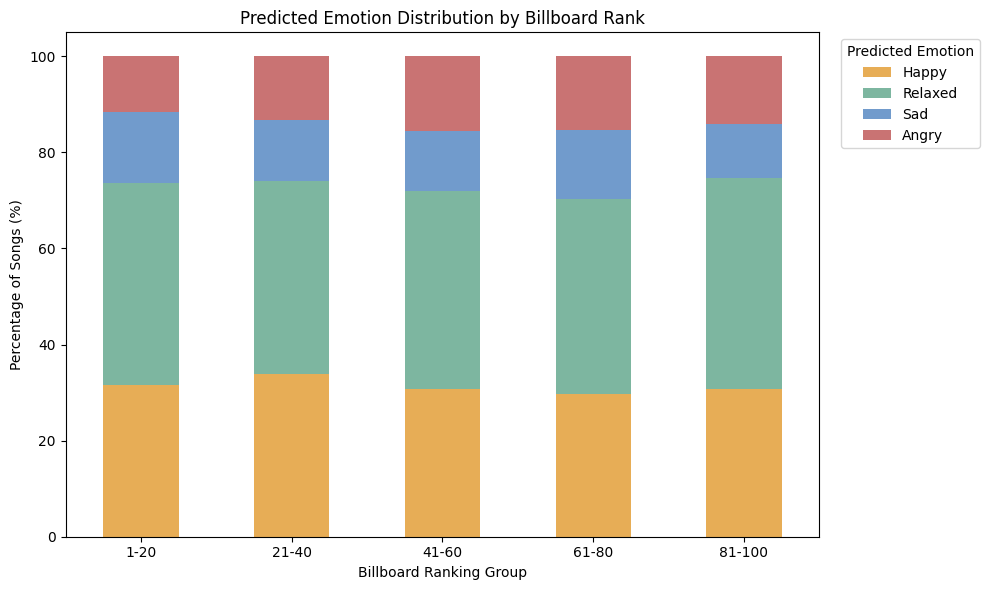

In [6]:

import pandas as pd
import matplotlib.pyplot as plt

rank_df = df.copy()
rank_df["rank"] = pd.to_numeric(
    rank_df["rank"], errors="coerce"
)

rank_df = rank_df.dropna(
    subset=["rank", "predicted_emotion"]
)

# Create ranking groups
rank_df["rank_group"] = pd.cut(
    rank_df["rank"],
    bins=[0, 20, 40, 60, 80, 100],
    labels=["1-20", "21-40", "41-60", "61-80", "81-100"]
)

emotion_order = ["Happy", "Relaxed", "Sad", "Angry"]

# Distribution within each ranking group
rank_emotion_pct = pd.crosstab(
    rank_df["rank_group"],
    rank_df["predicted_emotion"],
    normalize="index"
).reindex(
    columns=emotion_order, fill_value=0
) * 100

print("Predicted Emotion by Billboard Rank (%)")
display(rank_emotion_pct.round(2))

# Average and median rank by emotion
rank_summary = (
    rank_df.groupby("predicted_emotion")["rank"]
    .agg(["count", "mean", "median"])
    .reindex(emotion_order)
)

print("\nRanking Summary by Emotion")
display(rank_summary.round(2))

# Visualization
colors = ["#E7AD56", "#7DB6A0", "#719BCC", "#C97373"]

ax = rank_emotion_pct.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6),
    color=colors
)

ax.set_title("Predicted Emotion Distribution by Billboard Rank")
ax.set_xlabel("Billboard Ranking Group")
ax.set_ylabel("Percentage of Songs (%)")
ax.legend(title="Predicted Emotion", bbox_to_anchor=(1.02, 1))
ax.tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()


In [7]:

import numpy as np
import pandas as pd
from scipy.stats import chi2_contingency

# Use the rank_df created in the previous step
rank_labels = ["1-20", "21-40", "41-60", "61-80", "81-100"]
emotion_labels = ["Happy", "Relaxed", "Sad", "Angry"]

# Contingency table using actual song counts
contingency = pd.crosstab(
    rank_df["rank_group"],
    rank_df["predicted_emotion"]
).reindex(
    index=rank_labels,
    columns=emotion_labels,
    fill_value=0
)

display(contingency)

# Chi-square independence test
chi2, p_value, dof, expected = chi2_contingency(
    contingency
)

# Cramer's V: association strength
n = contingency.to_numpy().sum()
r, c = contingency.shape

cramers_v = np.sqrt(
    (chi2 / n) / min(r - 1, c - 1)
)

print(f"Chi-square statistic: {chi2:.4f}")
print(f"P-value: {p_value:.4f}")
print(f"Degrees of freedom: {dof}")
print(f"Cramer's V: {cramers_v:.4f}")

if p_value < 0.05:
    print("Statistical association detected.")
else:
    print("No statistically significant association detected.")

print("Association strength must be interpreted separately.")


predicted_emotion,Happy,Relaxed,Sad,Angry
rank_group,,,,
1-20,385,513,181,140
21-40,415,493,155,163
41-60,368,492,151,185
61-80,364,495,176,188
81-100,372,532,136,171


Chi-square statistic: 23.8376
P-value: 0.0214
Degrees of freedom: 12
Cramer's V: 0.0362
Statistical association detected.
Association strength must be interpreted separately.


In [8]:

import pandas as pd
import numpy as np
import statsmodels.formula.api as smf

# Prepare regression dataset
columns = [
    "song_id",
    "year",
    "rank",
    "prob_happy",
    "prob_relaxed",
    "prob_sad",
    "prob_angry"
]

reg_df = df[columns].copy()

# Convert variables to numeric
numeric_cols = [
    "year", "rank",
    "prob_happy", "prob_relaxed",
    "prob_sad", "prob_angry"
]

for col in numeric_cols:
    reg_df[col] = pd.to_numeric(
        reg_df[col], errors="coerce"
    )

# Remove incomplete records
reg_df = reg_df.dropna(
    subset=numeric_cols
).copy()

# Check probabilities
prob_cols = [
    "prob_happy", "prob_relaxed",
    "prob_sad", "prob_angry"
]

prob_sum = reg_df[prob_cols].sum(axis=1)

assert np.allclose(
    prob_sum, 1.0, atol=0.001
), "Emotion probabilities should sum to 1!"

# Check valid ranking
assert reg_df["rank"].between(1, 100).all()

reg_df["year"] = reg_df["year"].astype(int)

print("Regression samples:", len(reg_df))
display(reg_df.head())


Regression samples: 6075


,song_id,year,rank,prob_happy,prob_relaxed,prob_sad,prob_angry
0,1,1959,1,0.044382,0.128885,0.124242,0.702491
1,2,1959,2,0.055524,0.346569,0.414511,0.183396
2,3,1959,3,0.829837,0.147409,0.012689,0.010066
3,4,1959,4,0.824313,0.153370,0.012328,0.009990
4,5,1959,5,0.127874,0.569719,0.279449,0.022958


In [9]:

# Model 1: Year controls only
model_1 = smf.ols(
    "rank ~ C(year)",
    data=reg_df
).fit(cov_type="HC3")

# Model 2: Year + Emotion probabilities
# Relaxed is the reference category
model_2 = smf.ols(
    "rank ~ prob_happy + prob_sad + prob_angry + C(year)",
    data=reg_df
).fit(cov_type="HC3")

# Compare explanatory power
comparison = pd.DataFrame({
    "Model": [
        "Year Only",
        "Year + Emotion"
    ],
    "R-squared": [
        model_1.rsquared,
        model_2.rsquared
    ],
    "Adjusted R-squared": [
        model_1.rsquared_adj,
        model_2.rsquared_adj
    ]
})

display(comparison.round(4))


,Model,R-squared,Adjusted R-squared
0,Year Only,0.0009,-0.0097
1,Year + Emotion,0.0020,-0.0091


In [10]:

emotion_vars = [
    "prob_happy",
    "prob_sad",
    "prob_angry"
]

confidence_intervals = model_2.conf_int()

results = pd.DataFrame({
    "Coefficient": model_2.params[emotion_vars],
    "P-value": model_2.pvalues[emotion_vars],
    "CI Lower": confidence_intervals.loc[
        emotion_vars, 0
    ],
    "CI Upper": confidence_intervals.loc[
        emotion_vars, 1
    ]
})

print("Emotion Regression Results")
print("Reference emotion: Relaxed")

display(results.round(4))

print("\nR-squared improvement:",
      round(model_2.rsquared - model_1.rsquared, 4))


Emotion Regression Results
Reference emotion: Relaxed


,Coefficient,P-value,CI Lower,CI Upper
prob_happy,-1.0985,0.5653,-4.8433,2.6463
prob_sad,-3.8860,0.1386,-9.0293,1.2573
prob_angry,2.6643,0.1288,-0.7734,6.1021



R-squared improvement: 0.0011


Matched songs: 5867
Title mismatches: 0

Emotion Distribution by LDA Topic (%)


predicted_emotion,Happy,Relaxed,Sad,Angry
dominant_topic,,,,
Topic_1,31.41,47.17,12.87,8.55
Topic_2,36.57,46.85,5.63,10.96
Topic_3,35.75,39.39,19.24,5.62
Topic_4,33.02,46.87,14.04,6.07
Topic_5,9.11,31.03,3.69,56.16


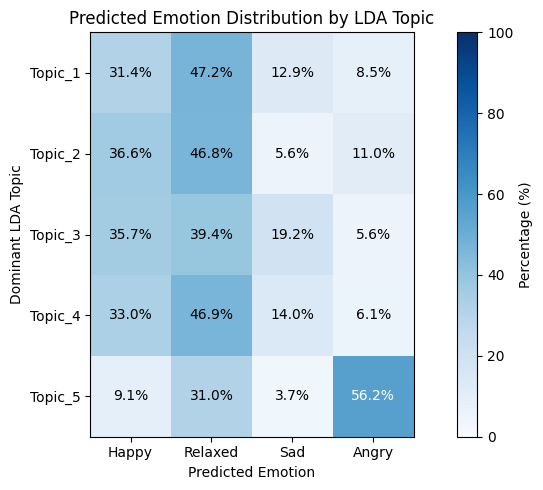

In [11]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Load LDA results
lda = pd.read_csv(
    "/content/LDA_Song_Level_For_Regression.csv",
    encoding="utf-8-sig"
)

lda = lda.rename(columns={
    "Year": "year",
    "Rank": "rank",
    "Song Title": "lda_song_title"
})

topic_cols = [
    "Topic_1", "Topic_2", "Topic_3",
    "Topic_4", "Topic_5"
]

# 2. Prepare matching keys
emotion_df = df.copy()

for frame in [emotion_df, lda]:
    frame["year"] = pd.to_numeric(
        frame["year"], errors="raise"
    ).astype(int)
    frame["rank"] = pd.to_numeric(
        frame["rank"], errors="raise"
    ).astype(int)

# 3. Merge on Year + Rank
merged = emotion_df.merge(
    lda[["year", "rank", "lda_song_title"] + topic_cols],
    on=["year", "rank"],
    how="inner",
    validate="one_to_one"
)

print("Matched songs:", len(merged))

# 4. Check that matched records refer to same song
def normalize_title(series):
    return (
        series.fillna("")
        .astype(str)
        .str.lower()
        .str.replace(r"[^a-z0-9]", "", regex=True)
    )

title_matches = (
    normalize_title(merged["song_title"])
    == normalize_title(merged["lda_song_title"])
)

print("Title mismatches:", (~title_matches).sum())

# 5. Assign each song its dominant LDA topic
merged["dominant_topic"] = (
    merged[topic_cols].idxmax(axis=1)
)

# 6. Emotion distribution within each topic
topic_emotion_pct = pd.crosstab(
    merged["dominant_topic"],
    merged["predicted_emotion"],
    normalize="index"
).reindex(
    index=topic_cols,
    columns=["Happy", "Relaxed", "Sad", "Angry"],
    fill_value=0
) * 100

print("\nEmotion Distribution by LDA Topic (%)")
display(topic_emotion_pct.round(2))

# 7. Heatmap
fig, ax = plt.subplots(figsize=(9, 5))

im = ax.imshow(
    topic_emotion_pct.values,
    cmap="Blues",
    vmin=0,
    vmax=100
)

ax.set_xticks(range(4))
ax.set_xticklabels(topic_emotion_pct.columns)
ax.set_yticks(range(5))
ax.set_yticklabels(topic_cols)

for i in range(5):
    for j in range(4):
        value = topic_emotion_pct.iloc[i, j]
        ax.text(
            j, i, f"{value:.1f}%",
            ha="center",
            va="center",
            color="white" if value > 50 else "black"
        )

ax.set_title(
    "Predicted Emotion Distribution by LDA Topic"
)
ax.set_xlabel("Predicted Emotion")
ax.set_ylabel("Dominant LDA Topic")

plt.colorbar(im, ax=ax, label="Percentage (%)")
plt.tight_layout()
plt.show()


In [12]:

# Topic 5 and Angry trends by decade

analysis = merged.copy()

analysis["decade"] = (
    analysis["year"].astype(int) // 10 * 10
)

analysis["is_topic5"] = (
    analysis["dominant_topic"] == "Topic_5"
)

analysis["is_angry"] = (
    analysis["predicted_emotion"] == "Angry"
)

results = []

for decade, group in analysis.groupby("decade"):

    topic5 = group[group["is_topic5"]]
    other = group[~group["is_topic5"]]

    results.append({
        "Decade": decade,
        "Songs": len(group),
        "Topic 5 Share (%)":
            group["is_topic5"].mean() * 100,
        "Overall Angry (%)":
            group["is_angry"].mean() * 100,
        "Angry within Topic 5 (%)":
            topic5["is_angry"].mean() * 100,
        "Angry outside Topic 5 (%)":
            other["is_angry"].mean() * 100
    })

trend_table = pd.DataFrame(results)

display(trend_table.round(2))


,Decade,Songs,Topic 5 Share (%),Overall Angry (%),Angry within Topic 5 (%),Angry outside Topic 5 (%)
0,1950,77,6.49,5.19,20.00,4.17
1,1960,880,3.75,5.91,24.24,5.19
2,1970,883,5.32,4.53,25.53,3.35
3,1980,942,4.25,4.56,22.50,3.77
4,1990,914,11.60,12.04,57.55,6.06
5,2000,931,22.99,21.80,57.48,11.16
6,2010,908,26.32,29.85,69.04,15.84
7,2020,332,38.55,31.02,60.16,12.75
